# Boolean network ensemble analysis

This notebook analyzes **our Boolean networks** and **the published networks** separately, then compares them.

- **Our models:** first view all our networks with **MDS and no cluster labels**. Only afterward check whether separate groups seem reasonable.
- **Their models:** reproduce the three reference groups using hierarchical clustering.
- **Comparison:** measure the number of different Boolean rules between each of our models and the **central model (medoid)** of each reference group.
- **Readable tree:** plot our networks together with the three central reference models—not all 1,000 reference models.

A *medoid* is the **real network with the smallest total distance to the other networks in its group**. It is a meaningful “middle model”; it is not an artificial average Boolean network.

Distances are counts of genes with different Boolean functions. MDS is a 2D approximation, so exact differences should be read from the distance tables, not measured from the plot.

## 1. Set input and output folders

Load the necessary Python packages and create the output folders. **The input `.bnet` files are never modified.**

In [20]:
from pathlib import Path  # 
import inspect 
import re  
import json 
import mpbn 
import numpy as np  
import pandas as pd  
import matplotlib.pyplot as plt 
import seaborn as sns  
from scipy.cluster.hierarchy import linkage, dendrogram 
from scipy.spatial.distance import squareform  
from sklearn.cluster import AgglomerativeClustering 
from sklearn.manifold import MDS  
from sklearn.metrics import silhouette_score  
from IPython.display import display  

OUR_INPUT = Path("../Results/Boolean_network_sampling_outputs")  # Our network files.
THEIR_INPUT = Path("../Data/models")  # Published network files.
OUTPUT = Path("../Results/Ensemble_analysis_outputs")  # Main results folder.
OUR_OUTPUT = OUTPUT / "Our_models"  # Outputs for our models only.
THEIR_OUTPUT = OUTPUT / "Their_models"  # Outputs for the published models only.

OUR_OUTPUT.mkdir(parents=True, exist_ok=True)  # Create our output folder.
THEIR_OUTPUT.mkdir(parents=True, exist_ok=True)  # Create their output folder.

print("Our models:", OUR_INPUT)
print("Their models:", THEIR_INPUT)
print("Results:", OUTPUT)

Our models: ../Results/Boolean_network_sampling_outputs
Their models: ../Data/models
Results: ../Results/Ensemble_analysis_outputs


## 2. Load both sets of Boolean networks

Read all numbered `.bnet` files from each input folder. The model count is detected automatically.

In [21]:
def model_order(path):
    # Prefer the number in names such as bn0.bnet, bn1.bnet, ... bn50.bnet.
    match = re.search(r"(\d+)$", path.stem)
    return (0, int(match.group(1))) if match else (1, path.stem)


def load_models(folder):
    # Find only Boolean-network files in this folder, not inside subfolders.
    paths = sorted(folder.glob("bn*.bnet"), key=model_order)
    if not paths:
        raise FileNotFoundError(f"No bn*.bnet files found in {folder.resolve()}")

    models = [mpbn.MPBooleanNetwork(str(path)) for path in paths]  # Load the models.
    rules = []  # Store each gene's Boolean function in a comparable form.

    for model in models:
        gene_rules = {}  # Boolean function for each gene in one model.
        for gene in model.keys():
            rule = model[gene]  # Read the original rule.
            gene_rules[gene] = (rule if rule is True or rule is False
                                else mpbn.minibn.struct_of_dnf(model.ba, rule))
        rules.append(gene_rules)  # Add this model's rules.

    genes = list(rules[0])  # Gene set of the first model.
    for name, one_model in zip(paths, rules):
        if set(one_model) != set(genes):
            raise ValueError(f"Gene set differs in {name}. Check the .bnet files.")

    return paths, rules, genes


our_paths, our_rules, our_genes = load_models(OUR_INPUT)  # Read our models.
their_paths, their_rules, their_genes = load_models(THEIR_INPUT)  # Read their models.

our_names = [path.name for path in our_paths]  # Our filenames.
their_names = [path.name for path in their_paths]  # Their filenames.

print(f"Our models: {len(our_rules)}; genes: {len(our_genes)}")
print(f"Their models: {len(their_rules)}; genes: {len(their_genes)}")

Our models: 50; genes: 39
Their models: 1000; genes: 39


## 3. Measure differences between Boolean networks

For each gene, compare its complete Boolean rule in two models. Add **1** when the rules differ and **0** when they match. We use exactly this definition for both ensembles and the comparison.

In [22]:
def rule_distance_matrix(models, genes):
    # Start with a square matrix of zero distances.
    distances = np.zeros((len(models), len(models)), dtype=np.int32)

    for gene in genes:
        # Give identical rules the same numeric ID.
        labels, _ = pd.factorize(pd.Series([model[gene] for model in models], dtype=object))
        # Count the gene when two models use different rules.
        distances += labels[:, None] != labels[None, :]

    return distances


our_distances = rule_distance_matrix(our_rules, our_genes)  # Our pairwise distances.
their_distances = rule_distance_matrix(their_rules, their_genes)  # Reference distances.

# Save the two within-ensemble distance tables separately.
pd.DataFrame(our_distances, index=our_names, columns=our_names).to_csv(
    OUR_OUTPUT / "rule_distance_matrix.csv"
)
pd.DataFrame(their_distances, index=their_names, columns=their_names).to_csv(
    THEIR_OUTPUT / "rule_distance_matrix.csv"
)

print("Our distance matrix:", our_distances.shape)
print("Their distance matrix:", their_distances.shape)

Our distance matrix: (50, 50)
Their distance matrix: (1000, 1000)


## 4. Our models: visualize first, without clustering

MDS places **our models alone** in two dimensions according to their rule differences. All dots have the same color because **no grouping has been assumed yet**. Look for separate clouds of points before interpreting clusters.

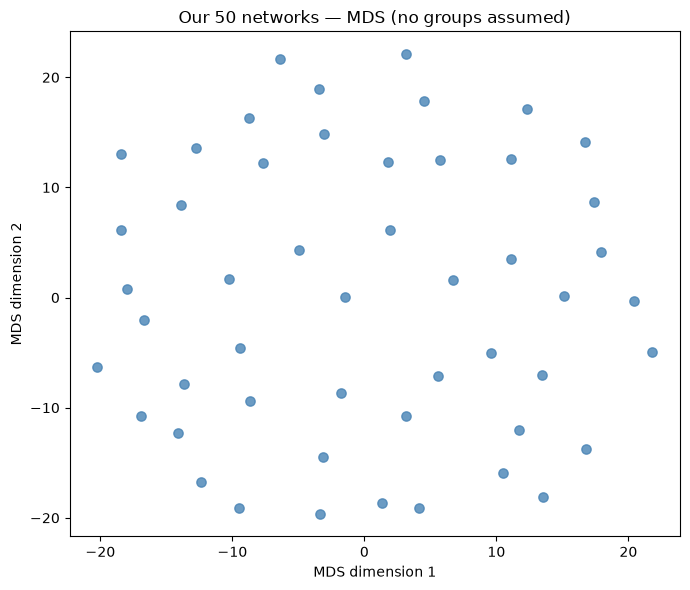

MDS stress: 112524.67
Distinct complete rule profiles: 50


In [23]:
def make_mds(distances):
    # Handle differences between older and newer scikit-learn versions.
    params = inspect.signature(MDS).parameters
    settings = {"n_components": 2, "random_state": 10, "n_init": 4, "max_iter": 300}
    if "init" in params:
        settings["init"] = "random"  # Keep initialization explicit.
    if "metric" in params and params["metric"].default is not True:
        settings["metric"] = "precomputed"  # Newer scikit-learn syntax.
    else:
        settings["dissimilarity"] = "precomputed"  # Older syntax.
    fit = MDS(**settings)
    return fit.fit_transform(distances), float(fit.stress_)


if len(our_rules) < 2:
    raise ValueError("MDS needs at least two models.")

if np.max(our_distances) == 0:
    # All our Boolean networks have identical rules: display them at one point.
    our_xy = np.zeros((len(our_rules), 2))
    our_stress = 0.0
else:
    our_xy, our_stress = make_mds(our_distances)

# Save coordinates without assigning groups.
pd.DataFrame({"model": our_names, "mds_x": our_xy[:, 0],
              "mds_y": our_xy[:, 1]}).to_csv(OUR_OUTPUT / "mds_coordinates.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 6))  # Create the 2D plot.
ax.scatter(our_xy[:, 0], our_xy[:, 1], s=45, alpha=0.8, color="steelblue")  # One color.
ax.set(title=f"Our {len(our_rules)} networks — MDS (no groups assumed)",
       xlabel="MDS dimension 1", ylabel="MDS dimension 2")
fig.tight_layout()
fig.savefig(OUR_OUTPUT / "mds_before_clustering.png", dpi=250)  # Save the image.
plt.show()

print("MDS stress:", round(our_stress, 2))
print("Distinct complete rule profiles:", len({tuple(m[g] for g in our_genes) for m in our_rules}))

The MDS plot above shows no clear clustering among the networks. Because diverse sampling is computationally expensive, generating 50 models was rarely achievable. The instance we saved, which successfully reached this target of 50 models, likely did so only because the sampling in that specific run was ultimately less diverse.

## 5. Our models: check whether groups seem reasonable

**This also tries hierarchical groupings with 2–5 clusters and measure their separation with the silhouette score. As shown in the output the seperation is weak

In [24]:
our_group_labels = None  # Default: no supported split.
our_group_table = pd.DataFrame(columns=["groups", "silhouette_score", "smallest_group"])

if len(our_rules) >= 4 and np.max(our_distances) > 0:
    candidates = []  # Compare several possible group counts.
    for k in range(2, min(5, len(our_rules) - 1) + 1):
        # Group models directly from the rule-distance matrix.
        fit = AgglomerativeClustering(n_clusters=k, metric="precomputed",
                                      linkage="average")
        labels = fit.fit_predict(our_distances)
        sizes = np.bincount(labels)  # Count members of each group.
        if len(np.unique(labels)) < 2:
            continue
        score = silhouette_score(our_distances, labels, metric="precomputed")
        candidates.append({"groups": k, "silhouette_score": float(score),
                           "smallest_group": int(sizes.min())})

    our_group_table = pd.DataFrame(candidates)  # Show all tested group counts.

# Save the exploratory scores even when the result is inconclusive.
our_group_table.to_csv(OUR_OUTPUT / "possible_group_scores.csv", index=False)
display(our_group_table)

if not our_group_table.empty:
    best = our_group_table.sort_values("silhouette_score", ascending=False).iloc[0]
    # 0.25 is an exploratory rule of thumb, not a statistical significance test.
    if best["silhouette_score"] >= 0.25 and best["smallest_group"] >= 2:
        k_best = int(best["groups"])
        our_group_labels = AgglomerativeClustering(
            n_clusters=k_best, metric="precomputed", linkage="average"
        ).fit_predict(our_distances)
        print(f"Possible separation into {k_best} exploratory groups.")
    else:
        print("No clearly separated groups under this exploratory criterion.")
else:
    print("Not enough distinct models to assess grouping.")

# Group IDs here are independent of the reference red/orange/green groups.
our_membership = pd.DataFrame({"model": our_names,
                               "exploratory_group": [f"Group {x+1}" for x in our_group_labels]
                               if our_group_labels is not None else [""] * len(our_names)})
our_membership.to_csv(OUR_OUTPUT / "exploratory_membership.csv", index=False)

,groups,silhouette_score,smallest_group
0,2,0.063921,12
1,3,0.060227,6
2,4,0.072060,6
3,5,0.067795,3


No clearly separated groups under this exploratory criterion.


## 6. Their models: define the three published reference groups

Use hierarchical clustering on the reference models **only**. The smallest group is displayed red, the largest orange, and the remaining group green, matching the earlier notebook's naming convention. The pilots cannot change these reference groups.

In [25]:
if len(their_rules) < 3:
    raise ValueError("Three reference groups require at least three reference models.")

# Assign exactly three reference groups from original Boolean-rule distances.
reference_fit = AgglomerativeClustering(
    n_clusters=3, metric="precomputed", linkage="average", compute_distances=True
).fit(their_distances)

ref_labels = reference_fit.labels_  # Numeric groups, names assigned next.
counts = {int(k): int(v) for k, v in zip(*np.unique(ref_labels, return_counts=True))}
ordered_ids = sorted(counts, key=lambda k: (counts[k], k))
ref_color_map = {ordered_ids[0]: "red", ordered_ids[1]: "green",
                 ordered_ids[2]: "orange"}
ref_colors = [ref_color_map[int(k)] for k in ref_labels]
ref_groups = {c: np.flatnonzero(np.array(ref_colors) == c)
              for c in ("red", "orange", "green")}

# Save memberships and model names for all reference networks.
reference_membership = pd.DataFrame({"model": their_names,
                                      "reference_cluster": ref_colors})
reference_membership.to_csv(THEIR_OUTPUT / "hierarchical_cluster_membership.csv",
                            index=False)

for color, members in ref_groups.items():
    print(f"{color.title()} reference group: {len(members)} models")
if len(their_rules) == 1000 and sorted(map(len, ref_groups.values())) != [5, 110, 885]:
    print("Note: your clusters do not match the 5/110/885 size pattern in the original notebook.")

Red reference group: 5 models
Orange reference group: 885 models
Green reference group: 110 models


## 7. Their models: MDS and a short dendrogram

Show the reference clusters on a 2D MDS map and summarize their hierarchical tree. The reference clusters are defined by the **original distance matrix**, not by positions on MDS.

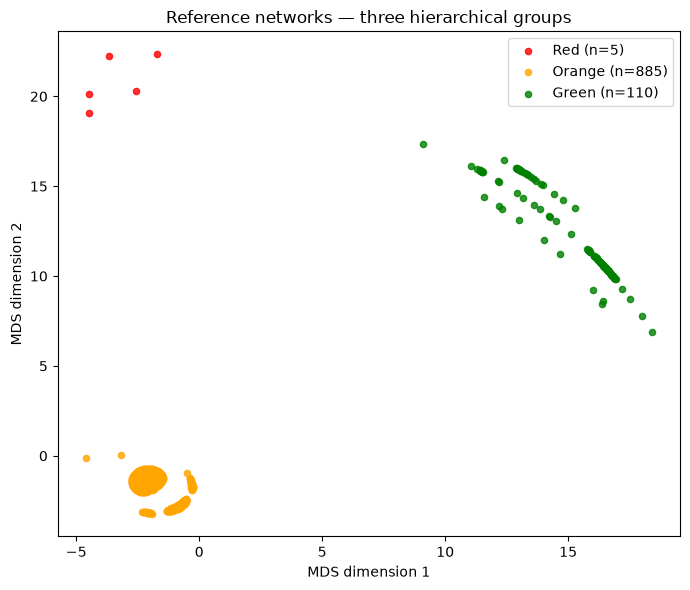

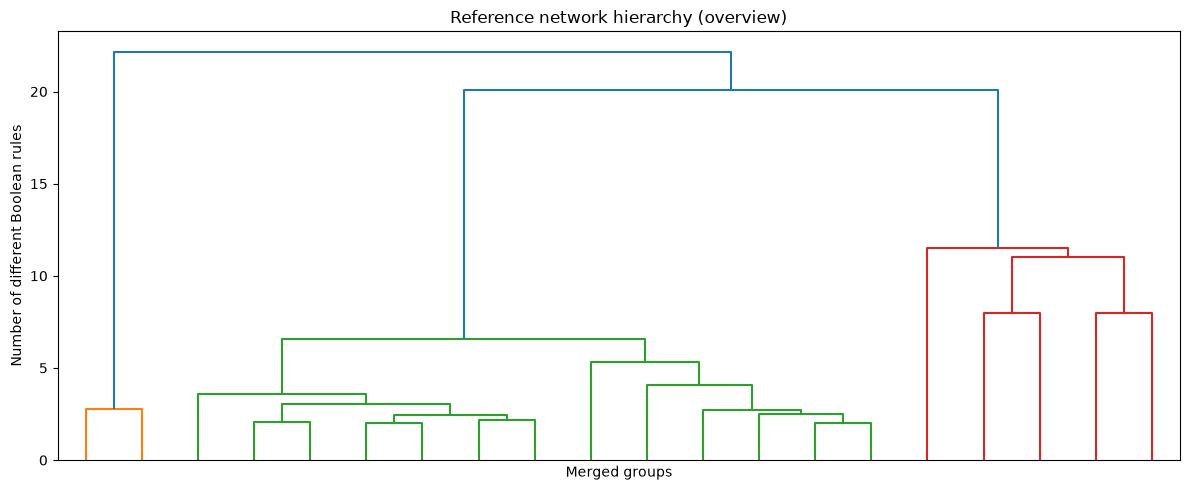

In [26]:
if np.max(their_distances) == 0:
    their_xy = np.zeros((len(their_rules), 2))
else:
    their_xy, _ = make_mds(their_distances)  # MDS uses the reference matrix.

# Export reference MDS positions.
pd.DataFrame({"model": their_names, "cluster": ref_colors,
              "mds_x": their_xy[:, 0], "mds_y": their_xy[:, 1]}).to_csv(
    THEIR_OUTPUT / "mds_coordinates.csv", index=False
)

fig, ax = plt.subplots(figsize=(7, 6))
for color, ids in ref_groups.items():
    ax.scatter(their_xy[ids, 0], their_xy[ids, 1], s=20, alpha=0.8,
               color=color, label=f"{color.title()} (n={len(ids)})")
ax.set(title="Reference networks — three hierarchical groups",
       xlabel="MDS dimension 1", ylabel="MDS dimension 2")
ax.legend()
fig.tight_layout()
fig.savefig(THEIR_OUTPUT / "mds_hierarchical_groups.png", dpi=250)
plt.show()

# Use a compact dendrogram, rather than labeling every one of 1,000 tips.
branch_counts = np.zeros(len(reference_fit.children_))
for i, children in enumerate(reference_fit.children_):
    branch_counts[i] = sum(1 if child < len(their_rules)
                           else branch_counts[child-len(their_rules)] for child in children)
reference_linkage = np.column_stack([reference_fit.children_,
                                     reference_fit.distances_, branch_counts])
fig, ax = plt.subplots(figsize=(12, 5))
dendrogram(reference_linkage, truncate_mode="lastp", p=20,
           no_labels=True, ax=ax)  # Show the last 20 branches only.
ax.set(title="Reference network hierarchy (overview)",
       ylabel="Number of different Boolean rules", xlabel="Merged groups")
fig.tight_layout()
fig.savefig(THEIR_OUTPUT / "hierarchical_tree_overview.png", dpi=250)
plt.show()

## 8. Compare Boolean-rule variability in both ensembles

Count **how many different Boolean functions** each gene receives across our models and across their models. A value of 1 means the rule does not change in that ensemble.

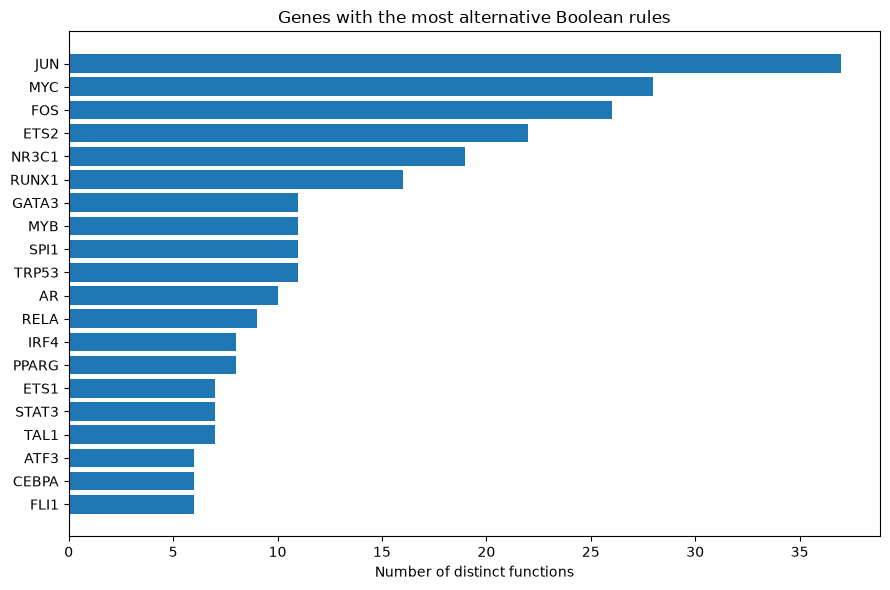

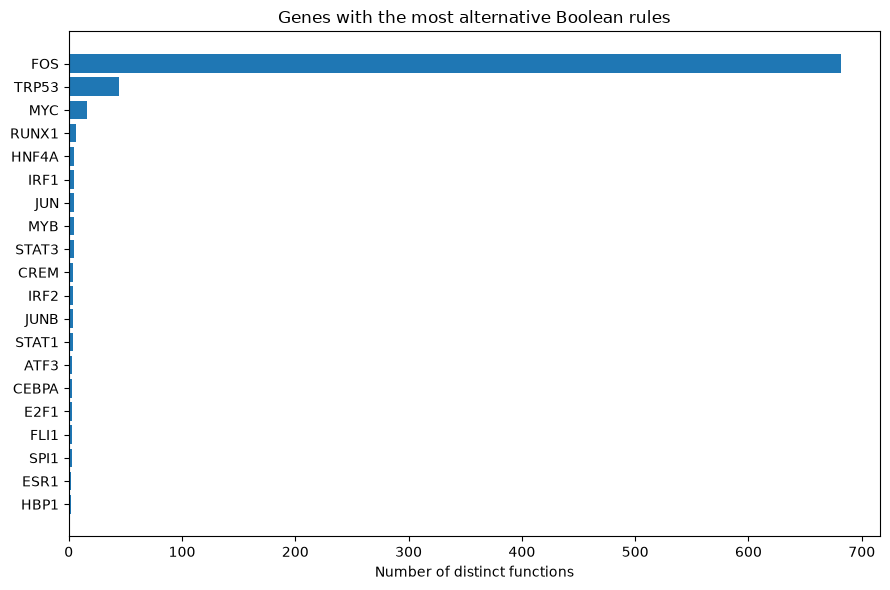

Invariant genes in our ensemble: 4
Invariant genes in their ensemble: 12


In [27]:
def save_gene_variability(models, genes, outfolder):
    # Count unique Boolean functions per gene across the entire ensemble.
    table = pd.DataFrame({"gene": genes,
                          "distinct_functions": [len({m[g] for m in models}) for g in genes]})
    table = table.sort_values(["distinct_functions", "gene"], ascending=[False, True])
    table.to_csv(outfolder / "gene_function_variability.csv", index=False)

    # Plot up to 20 genes with the most alternative rules.
    top = table.head(20).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(top["gene"], top["distinct_functions"])
    ax.set(title="Genes with the most alternative Boolean rules",
           xlabel="Number of distinct functions")
    fig.tight_layout()
    fig.savefig(outfolder / "gene_function_variability.png", dpi=250)
    plt.show()
    return table


our_variability = save_gene_variability(our_rules, our_genes, OUR_OUTPUT)
their_variability = save_gene_variability(their_rules, their_genes, THEIR_OUTPUT)
print("Invariant genes in our ensemble:", sum(our_variability["distinct_functions"] == 1))
print("Invariant genes in their ensemble:", sum(their_variability["distinct_functions"] == 1))

## 9. Compare rule complexity in both ensembles

A Boolean function is made of one or more **clauses**. Count clauses per function and regulators per clause, then save the statistics and percentage-distribution plots for each ensemble.

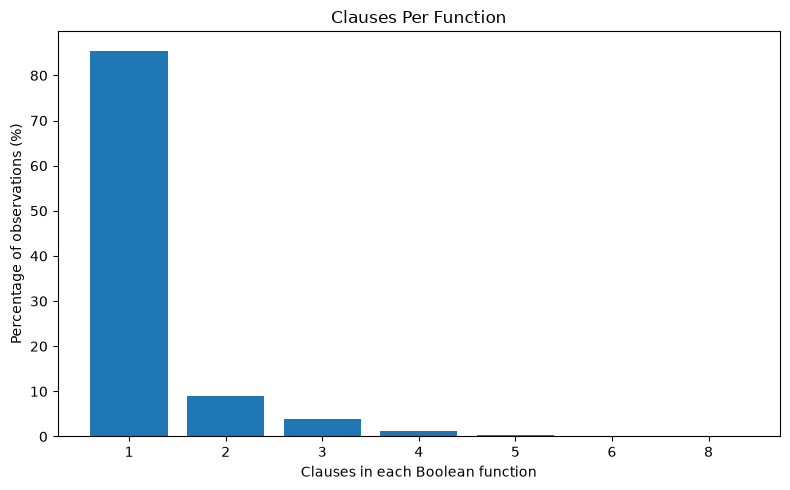

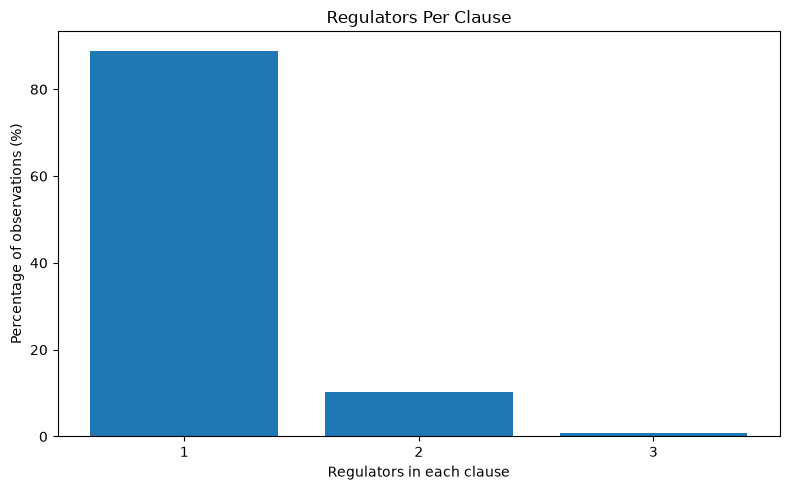

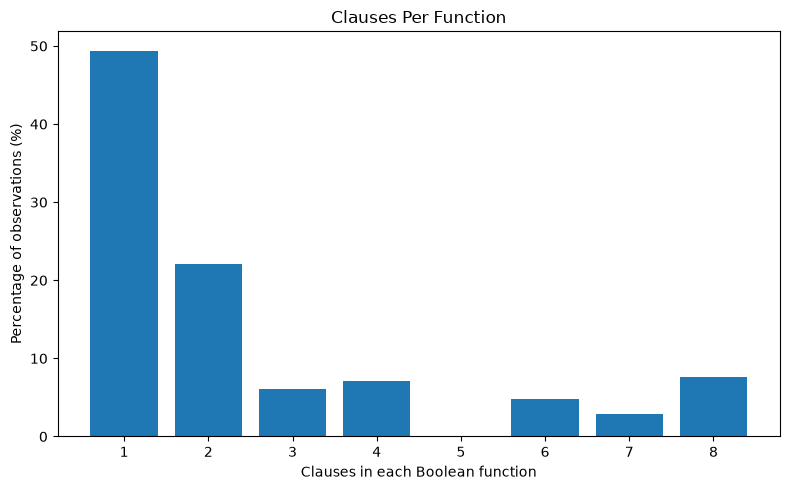

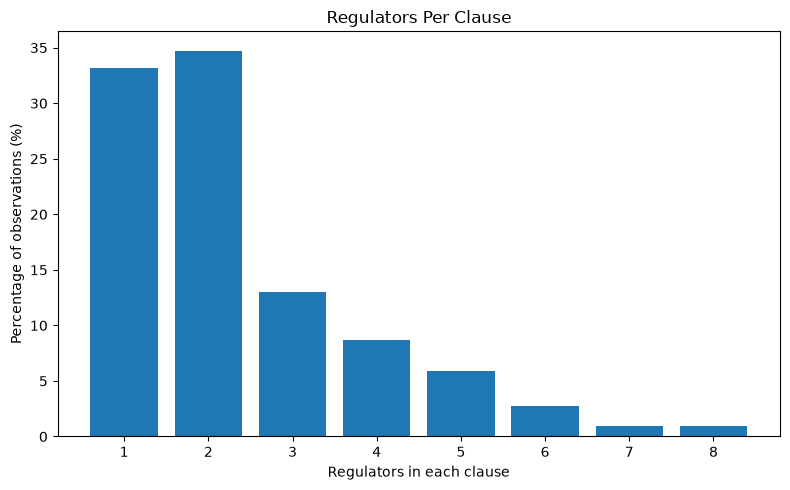

,measure,mean,median,n
0,clauses_per_function,1.225128,1.0,1950
1,regulators_per_clause,1.118878,1.0,2389


,measure,mean,median,n
0,clauses_per_function,2.502436,2.0,39000
1,regulators_per_clause,2.357416,2.0,97595


In [28]:
def rule_complexity(rule):
    # Constant True/False rules have no regulators; count one simple clause, as in the original notebook.
    if rule is True or rule is False:
        return 1, [1]
    # Nonconstant rules contain clauses, each with several regulators.
    return len(rule), [len(clause) for clause in rule]


def save_complexity(models, outfolder):
    clause_counts, regulator_counts = [], []
    for model in models:
        for rule in model.values():
            clauses, regulators = rule_complexity(rule)
            clause_counts.append(clauses)  # Clauses per function.
            regulator_counts.extend(regulators)  # Regulators per clause.

    table = pd.DataFrame([
        {"measure": "clauses_per_function", "mean": np.mean(clause_counts),
         "median": np.median(clause_counts), "n": len(clause_counts)},
        {"measure": "regulators_per_clause", "mean": np.mean(regulator_counts),
         "median": np.median(regulator_counts), "n": len(regulator_counts)},
    ])
    table.to_csv(outfolder / "rule_complexity_summary.csv", index=False)

    for values, name, xlabel in [
        (clause_counts, "clauses_per_function", "Clauses in each Boolean function"),
        (regulator_counts, "regulators_per_clause", "Regulators in each clause"),
    ]:
        counts = pd.Series(values).value_counts(normalize=True).sort_index() * 100
        fig, ax = plt.subplots(figsize=(8, 5))
        ax.bar(counts.index.astype(str), counts.values)
        ax.set(title=name.replace("_", " ").title(), xlabel=xlabel,
               ylabel="Percentage of observations (%)")
        fig.tight_layout()
        fig.savefig(outfolder / f"{name}.png", dpi=250)
        plt.show()
    return table


our_complexity = save_complexity(our_rules, OUR_OUTPUT)
their_complexity = save_complexity(their_rules, THEIR_OUTPUT)
display(our_complexity)
display(their_complexity)

## 10. Their models: examine each reference group separately

Repeat the rule-variability and complexity analysis for the three fixed reference groups. These groups correspond to the reference clustering in Section 7.

In [29]:
reference_group_summary = []  # One summary row per reference group.

for color, ids in ref_groups.items():
    group_models = [their_rules[i] for i in ids]  # Models belonging to this group.
    counts = [len({model[g] for model in group_models}) for g in their_genes]
    table = pd.DataFrame({"gene": their_genes, "distinct_functions": counts})
    table.to_csv(THEIR_OUTPUT / f"{color}_gene_function_variability.csv", index=False)

    # Compute rule complexity within this group.
    values = [rule_complexity(rule)[0] for model in group_models
              for rule in model.values()]
    reference_group_summary.append({"group": color, "models": len(ids),
                                     "invariant_genes": int(sum(np.array(counts) == 1)),
                                     "mean_clauses_per_function": float(np.mean(values))})

# Save a single small table summarizing all three reference groups.
reference_group_summary = pd.DataFrame(reference_group_summary)
reference_group_summary.to_csv(THEIR_OUTPUT / "reference_group_summary.csv", index=False)
display(reference_group_summary)

,group,models,invariant_genes,mean_clauses_per_function
0,red,5,23,1.338462
1,orange,885,35,2.512821
2,green,110,27,2.471795


### Compare rule complexity within any identified groups

For the **three published groups**, show the same three complexity measures as the original notebook: clauses per function, clauses in invariant functions, and regulators per clause. Do the same for our groups **only if Section 5 found reasonable exploratory groups**. Save gene-level invariant/variable reports separately.

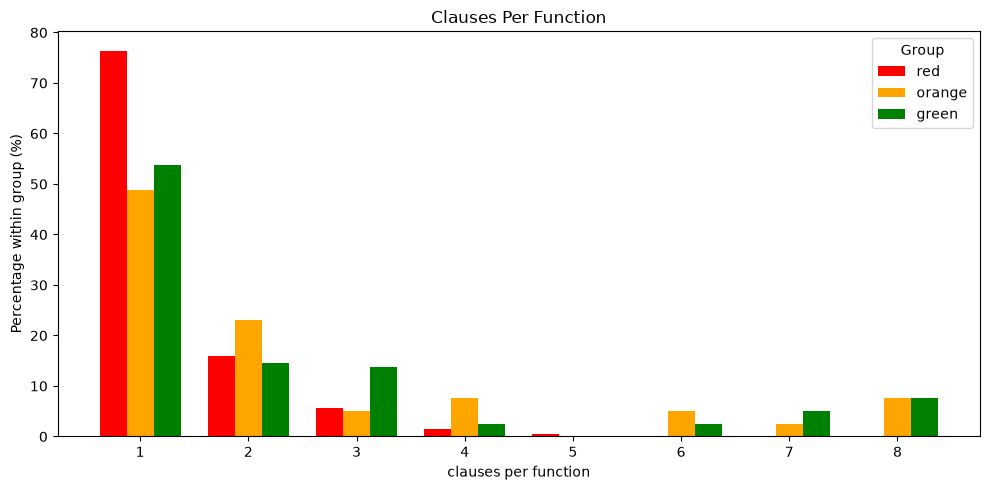

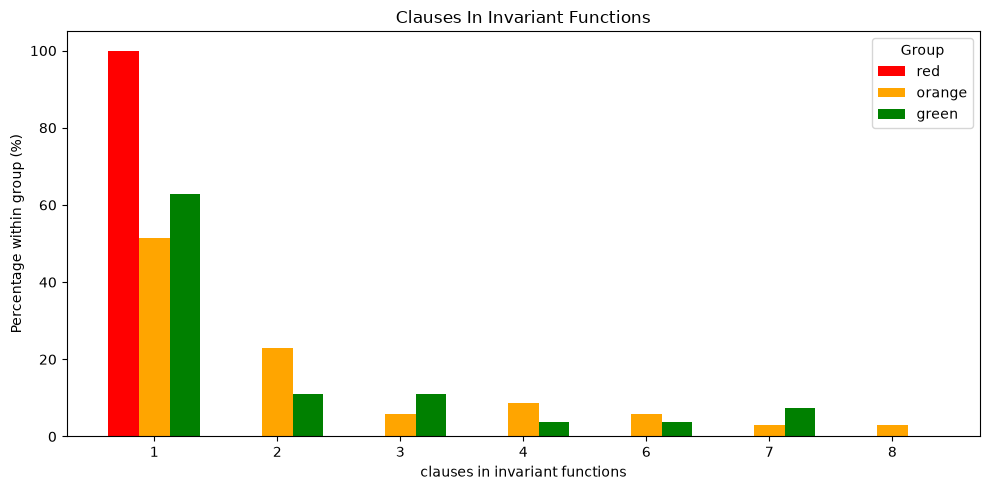

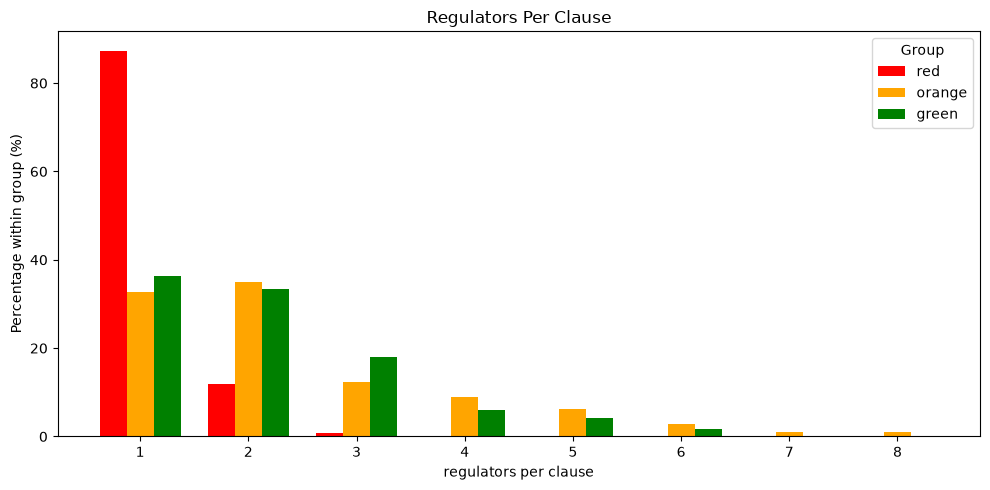

No exploratory group-specific complexity plots for our models.


In [30]:
def summarize_model_groups(models, genes, groups, folder, prefix):
    # Calculate these three distributions separately inside each group.
    distributions = {"clauses_per_function": {},
                     "clauses_in_invariant_functions": {},
                     "regulators_per_clause": {}}

    for name, indices in groups.items():
        selected = [models[i] for i in indices]  # Models in this group.
        clauses, regulators, invariant_clauses = [], [], []
        report = []  # Plain-English summary of every gene's rules.

        for gene in genes:
            rules = {model[gene] for model in selected}  # Distinct rules for this gene.
            report.append(f"{gene}: {len(rules)} different Boolean rules")
            if len(rules) == 1:
                invariant_clauses.append(rule_complexity(next(iter(rules)))[0])

        for model in selected:
            for rule in model.values():
                clause_count, regulator_counts = rule_complexity(rule)
                clauses.append(clause_count)
                regulators.extend(regulator_counts)

        distributions["clauses_per_function"][name] = clauses
        distributions["clauses_in_invariant_functions"][name] = invariant_clauses
        distributions["regulators_per_clause"][name] = regulators

        # Save one short text report per group.
        (folder / f"{prefix}_{name}_function_report.txt").write_text(
            f"Models in {name}: {len(selected)}\n\n" + "\n".join(report), encoding="utf-8"
        )

    # Create one bar plot for each complexity measure.
    for metric, values_by_group in distributions.items():
        all_values = sorted(set().union(*(set(v) for v in values_by_group.values())))
        if not all_values:
            continue
        names = list(values_by_group)
        positions = np.arange(len(all_values))
        width = min(0.75 / len(names), 0.35)
        fig, ax = plt.subplots(figsize=(10, 5))

        for i, name in enumerate(names):
            values = values_by_group[name]
            portions = [100 * values.count(v) / len(values) if values else 0
                        for v in all_values]
            offset = (i - (len(names) - 1) / 2) * width
            ax.bar(positions + offset, portions, width=width, label=str(name),
                   color=name if name in {"red", "orange", "green"} else None)

        ax.set_xticks(positions, labels=all_values)
        ax.set(title=metric.replace("_", " ").title(),
               xlabel=metric.replace("_", " "), ylabel="Percentage within group (%)")
        ax.legend(title="Group")
        fig.tight_layout()
        fig.savefig(folder / f"{prefix}_{metric}_by_group.png", dpi=250)
        plt.show()


# Reference groups always have three fixed hierarchical assignments.
summarize_model_groups(their_rules, their_genes, ref_groups, THEIR_OUTPUT, "reference")

# Our groups are optional; no comparison is forced if they were not supported.
if our_group_labels is not None:
    exploratory_groups = {f"group_{g+1}": np.flatnonzero(our_group_labels == g)
                          for g in np.unique(our_group_labels)}
    summarize_model_groups(our_rules, our_genes, exploratory_groups,
                           OUR_OUTPUT, "exploratory")
else:
    print("No exploratory group-specific complexity plots for our models.")

## 11. Find the central model of each reference group

For each red/orange/green group, select its **medoid**: the existing reference model with the smallest total number of rule differences to other members of that group. This is the “middle point” used in the comparison.

In [31]:
shared_genes = [g for g in their_genes if g in set(our_genes)]
if not shared_genes:
    raise ValueError("The two model sets have no shared gene names.")

print(f"Comparable genes: {len(shared_genes)}")
if set(shared_genes) != set(their_genes) or set(shared_genes) != set(our_genes):
    print("IMPORTANT: cross-ensemble distances use only shared genes.")
    print("Our extra genes:", sorted(set(our_genes) - set(shared_genes)))
    print("Their extra genes:", sorted(set(their_genes) - set(shared_genes)))

# Recalculate reference distances using exactly the genes shared by both sets.
reference_shared_distances = rule_distance_matrix(their_rules, shared_genes)

medoid_indices = {}  # Store the original reference index for each central model.
for color, ids in ref_groups.items():
    group_distances = reference_shared_distances[np.ix_(ids, ids)]
    # Find the group member with the smallest sum of distances to its peers.
    center_position = int(np.argmin(group_distances.sum(axis=1)))
    medoid_indices[color] = int(ids[center_position])

medoid_table = pd.DataFrame([
    {"reference_group": color, "center_model": their_names[medoid_indices[color]],
     "group_size": len(ref_groups[color])}
    for color in ("red", "orange", "green")
])
medoid_table.to_csv(OUTPUT / "reference_group_center_models.csv", index=False)
display(medoid_table)

Comparable genes: 21
IMPORTANT: cross-ensemble distances use only shared genes.
Our extra genes: ['AR', 'CREB1', 'E2F6', 'ELF3', 'ETS1', 'ETS2', 'GATA3', 'IRF4', 'LEF1', 'MITF', 'NR3C1', 'PAX5', 'PPARG', 'TAL1', 'TCF4', 'TCF7', 'TCF7L2', 'TFAP2A']
Their extra genes: ['ATF7', 'EBF1', 'ESR1', 'FOXO3', 'FOXP2', 'HBP1', 'HNF4A', 'IKZF1', 'IRF1', 'JUNB', 'KLF1', 'KLF6', 'NRF1', 'STAT6', 'TBP', 'TBX21', 'TCF12', 'ZEB2']


,reference_group,center_model,group_size
0,red,bn966.bnet,5
1,orange,bn44.bnet,885
2,green,bn789.bnet,110


## 12. Calculate distances from our models to the three centers

Each value is the **number of genes with different Boolean rules** between one of our networks and the medoid of the red, orange, or green reference group. Unlike a mean-to-all-members comparison, this uses one real central network per group.

In [32]:
centers = ["red", "orange", "green"]
central_models = [their_rules[medoid_indices[c]] for c in centers]

# Compare all our models with all three central reference networks.
combined = our_rules + central_models
n_our = len(our_rules)
center_distance_matrix = rule_distance_matrix(combined, shared_genes)
our_to_centers = center_distance_matrix[:n_our, n_our:]  # 50 x 3 if 50 models.

# For each model, identify the nearest central reference model.
nearest_center = np.argmin(our_to_centers, axis=1)
comparison = pd.DataFrame({"our_model": our_names,
                           "distance_to_red_center": our_to_centers[:, 0],
                           "distance_to_orange_center": our_to_centers[:, 1],
                           "distance_to_green_center": our_to_centers[:, 2],
                           "nearest_reference_center": [centers[i] for i in nearest_center],
                           "shared_genes_compared": len(shared_genes)})

# Mark ties separately, because equal distances do not identify one clear family.
minimums = our_to_centers.min(axis=1)
tie_count = (our_to_centers == minimums[:, None]).sum(axis=1)
comparison.loc[tie_count > 1, "nearest_reference_center"] = "tie"

comparison.to_csv(OUTPUT / "our_models_distance_to_reference_centers.csv", index=False)
display(comparison)
print("Closest reference centers:")
print(comparison["nearest_reference_center"].value_counts())

,our_model,distance_to_red_center,distance_to_orange_center,distance_to_green_center,nearest_reference_center,shared_genes_compared
0,bn0.bnet,17,19,18,red,21
1,bn1.bnet,16,19,19,red,21
2,bn2.bnet,16,19,18,red,21
3,bn3.bnet,17,19,18,red,21
4,bn4.bnet,17,19,19,red,21
5,bn5.bnet,17,19,18,red,21
6,bn6.bnet,16,19,18,red,21
7,bn7.bnet,17,19,19,red,21
8,bn8.bnet,16,19,17,red,21
9,bn9.bnet,18,19,18,tie,21


Closest reference centers:
nearest_reference_center
red      44
tie       4
green     2
Name: count, dtype: int64


## 13. Visualize the three **actual** center distances in 2D

Each axis is the number of differing Boolean rules, **not an MDS coordinate**. Read red vs orange, red vs green, and orange vs green to see which center is closer to each model. No artificial jitter or point labels are added.

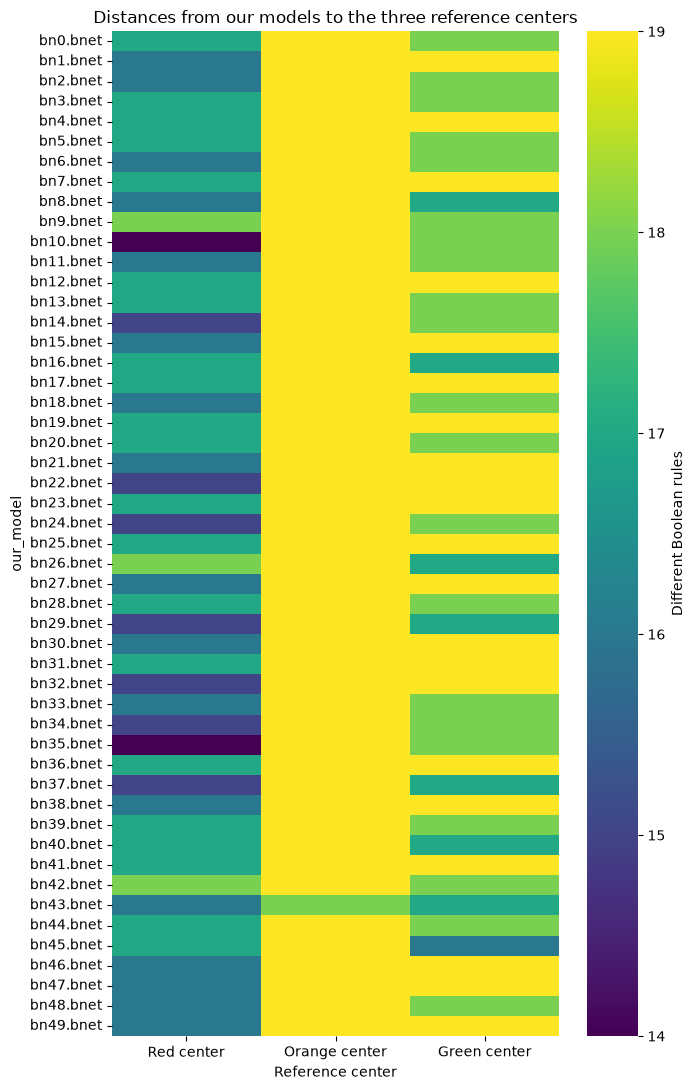

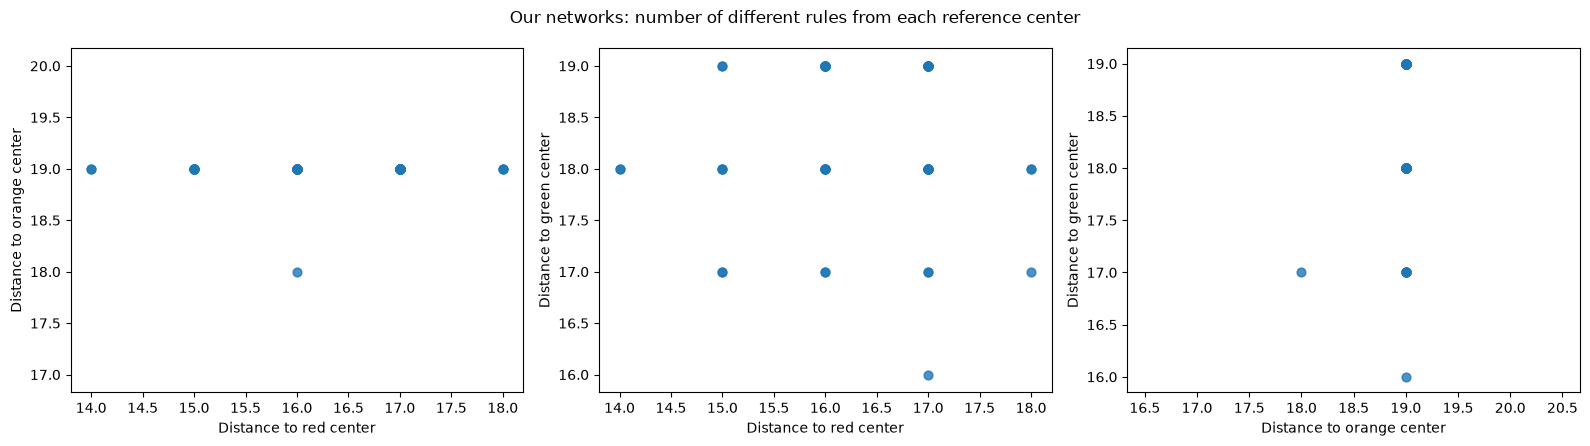

In [33]:
# A compact heatmap shows all models against the three center networks.
heat = comparison.set_index("our_model")[[f"distance_to_{c}_center" for c in centers]]
heat.columns = ["Red center", "Orange center", "Green center"]
fig, ax = plt.subplots(figsize=(7, max(6, 0.22 * len(our_rules))))
sns.heatmap(heat, cmap="viridis", ax=ax, cbar_kws={"label": "Different Boolean rules"})
ax.set(title="Distances from our models to the three reference centers", xlabel="Reference center")
fig.tight_layout()
fig.savefig(OUTPUT / "distance_to_centers_heatmap.png", dpi=250)
plt.show()

# Show all three pairs of distances as simple 2D scatterplots.
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (i, j) in zip(axes, [(0, 1), (0, 2), (1, 2)]):
    ax.scatter(our_to_centers[:, i], our_to_centers[:, j], s=40, alpha=0.8)
    ax.set(xlabel=f"Distance to {centers[i]} center",
           ylabel=f"Distance to {centers[j]} center")
    ax.set_aspect("equal", adjustable="datalim")
fig.suptitle("Our networks: number of different rules from each reference center")
fig.tight_layout()
fig.savefig(OUTPUT / "distance_to_centers_2d.png", dpi=250)
plt.show()

## 14. Readable hierarchical comparison: our models + three centers

Build a small average-linkage tree using **our models and one medoid from each reference group**. The published groups remain fixed. This tree is only a readable comparison of **our models to three representatives**, not a hierarchical clustering of all 1,000 reference models together.

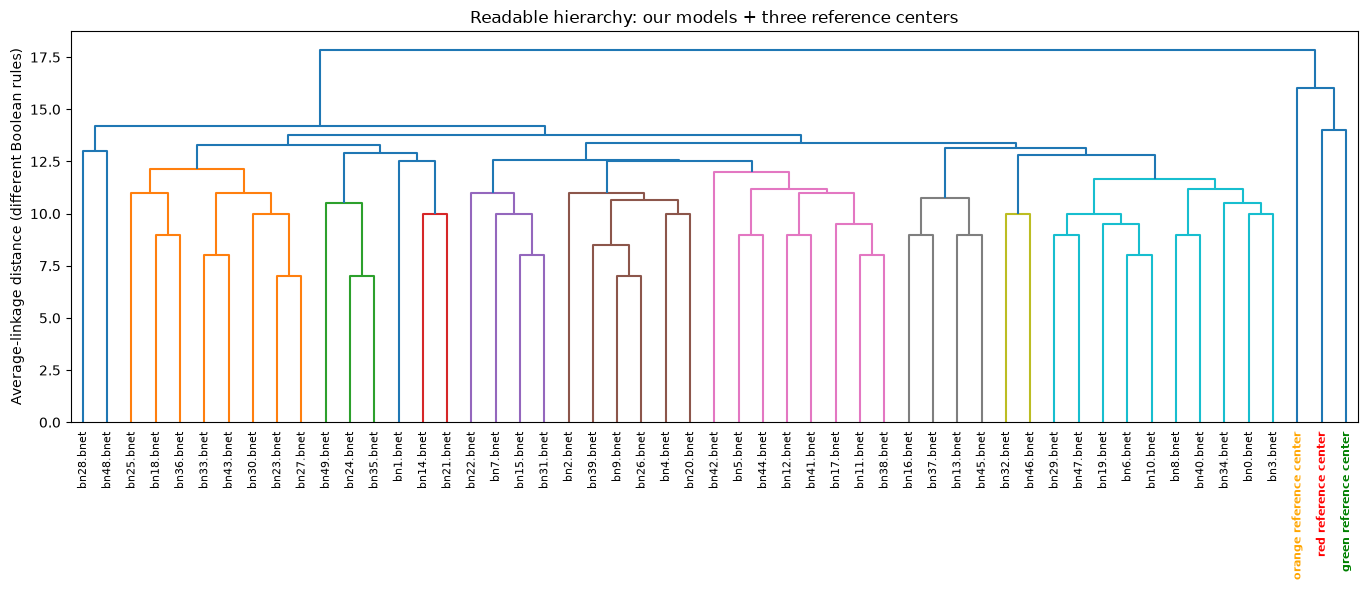

In [34]:
# Use the pairwise rule distances for our models and the three medoids.
small_tree = linkage(squareform(center_distance_matrix, checks=True), method="average")
leaf_names = our_names + [f"{color} reference center" for color in centers]

fig, ax = plt.subplots(figsize=(max(12, 0.26 * len(leaf_names)), 6))
tree = dendrogram(small_tree, labels=leaf_names, leaf_rotation=90,
                  leaf_font_size=8, ax=ax)

# Emphasize only the three reference-center leaves.
for tick in ax.get_xmajorticklabels():
    if tick.get_text().endswith("reference center"):
        tick.set_fontweight("bold")
        tick.set_color(tick.get_text().split()[0])

ax.set(title="Readable hierarchy: our models + three reference centers",
       ylabel="Average-linkage distance (different Boolean rules)")
fig.tight_layout()
fig.savefig(OUTPUT / "readable_hierarchical_comparison.png", dpi=250)
plt.show()

## 15. Save an analysis summary

Record the input files, number of models, number of comparable genes, and the grouping methods. All output files are in the main results folder or its **Our_models** and **Their_models** subfolders.

In [35]:
summary = {"our_input": str(OUR_INPUT), "their_input": str(THEIR_INPUT),
           "our_models": len(our_rules), "their_models": len(their_rules),
           "our_genes": len(our_genes), "their_genes": len(their_genes),
           "shared_genes": len(shared_genes),
           "reference_group_sizes": {c: len(ref_groups[c]) for c in centers},
           "our_exploratory_groups": (len(np.unique(our_group_labels))
                                       if our_group_labels is not None else None),
           "comparison_metric": "gene-level Boolean-rule disagreement",
           "reference_middle_point": "medoid (real central reference model)"}

with (OUTPUT / "analysis_summary.json").open("w", encoding="utf-8") as handle:
    json.dump(summary, handle, indent=2)  # Make the saved summary easy to read.

print("All outputs saved to:", OUTPUT.resolve())
print("  - Our_models: independent analysis of our ensemble")
print("  - Their_models: independent analysis of reference ensemble")
print("  - Output root: comparison tables and figures")

All outputs saved to: /home/eren/CSBC_CLEAN/Results/Ensemble_analysis_outputs
  - Our_models: independent analysis of our ensemble
  - Their_models: independent analysis of reference ensemble
  - Output root: comparison tables and figures
